# Vision — Anotasi Sendiri untuk Deteksi Objek (auto-label YOLO)
**Kapan dipakai:** gambar **belum punya kotak sama sekali** dan kotaknya harus dibuat sendiri.

**Bukan untuk:** soal yang sudah memberi kotak (COCO JSON, YOLO `.txt`, VOC `.xml`). Untuk itu
langsung pakai `vision/deteksi` (melatih dari COCO) atau `vision/konversi_anotasi` (ubah format).

**Langkah:** YOLO pretrained menebak kotak (auto-label) → lihat grid hasilnya → perbaiki yang
salah → susun folder YOLO → fine-tune → cek mAP. Tanpa GUI, tanpa internet.

**Auto-label hanya bisa menebak 80 kelas dataset COCO** (person, car, cat, dog, ...). Objek soal
di luar daftar itu (misalnya strip tanggal di label obat) tidak akan terdeteksi; labeli manual
di CVAT/Label Studio, lalu lanjut dari `vision/deteksi`.

**Data demo:** `pets/tanpa_label` = 300 foto kucing/anjing Oxford-IIIT Pet tanpa kotak. Isinya
kotor seperti data asli: ukuran 100–2000 px, beberapa file sebenarnya GIF/PNG walau berekstensi
`.jpg`, ada yang grayscale atau RGBA. Kunci jawaban (spesies dari nama file) baru dipakai di sel
terakhir untuk mengukur mutu label kita.

In [1]:
import glob
import os
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Rectangle
from PIL import Image
from sklearn.model_selection import train_test_split
from ultralytics import YOLO

## Konfigurasi
Dua "COCO" yang berbeda: **dataset COCO** (80 kelas, dipakai melatih `yolov8n.pt`) dan **format
COCO** (file JSON anotasi). `CLASS_MAP` merujuk ke **dataset** COCO: nomor kelas tebakan model
→ nomor kelas kita. Kelas yang tidak ada di `CLASS_MAP` dibuang.

In [2]:
DATA_FOLDER = "../../../data_latihan/vision/pets"   # GANTI saat lomba
IMAGE_FOLDER = f"{DATA_FOLDER}/tanpa_label"      # folder gambar yang belum berlabel
IMAGE_EXTENSION = ".jpg"
WEIGHTS = "../../../pretrained/yolov8n/yolov8n.pt"

# semua hasil ke luar folder repo (JANGAN diarahkan ke folder data soal)
OUTPUT_FOLDER = "../../../outputs/vision/anotasi_deteksi"
LABEL_FOLDER = f"{OUTPUT_FOLDER}/labels_auto"     # file .txt hasil auto-label
DATASET_FOLDER = f"{OUTPUT_FOLDER}/dataset_auto"  # folder YOLO images/ + labels/ untuk fine-tune
RUNS_FOLDER = os.path.abspath(f"{OUTPUT_FOLDER}/runs")   # ultralytics butuh path lengkap

CLASS_MAP = {15: 0, 16: 1}                 # dataset COCO: 15 = cat, 16 = dog
CLASS_NAMES = {0: "kucing", 1: "anjing"}   # nomor kelas kita → nama
# CLASS_MAP = {0: 0}  CLASS_NAMES = {0: "pejalan"}   # contoh lain: COCO 0 = person
IMAGE_SIZE = 640
EPOCHS = 10
BATCH_SIZE = 8        # kehabisan memori GPU? turunkan ke 4
VAL_FRACTION = 0.2
N_GRID = 8            # jumlah gambar per grid tinjauan (genap)
MIN_CONFIDENCE = 0.25   # kotak dengan keyakinan di bawah ini dibuang
MIN_AREA = 0.01       # kotak lebih kecil dari 1% gambar dibuang
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = 0
# Koreksi manual: isi SETELAH melihat grid, lalu jalankan ulang mulai dari sel koreksi
DELETE_ROWS = {}      # contoh: {"Abyssinian_10": [1]} -> hapus baris ke-1 (mulai dari 0)
CHANGE_CLASS = {}     # contoh: {"Abyssinian_10": {0: 1}} -> baris ke-0 jadi kelas 1
ADD_BOXES = {}        # contoh: {"Abyssinian_10": [(0, 100, 50, 220, 400)]}
#                       = (kelas, kiri, atas, kanan, bawah) dalam piksel

## Baca data + cek format file
Ekstensi `.jpg` belum tentu isinya JPEG. `Image.open(...).format` membaca isi file yang
sebenarnya. `mode` RGB = berwarna; `L` = abu-abu; `RGBA` = ada kanal transparan;
`P` = palet (GIF).

In [3]:
image_paths = sorted(glob.glob(f"{IMAGE_FOLDER}/*{IMAGE_EXTENSION}"))
image_names = []
rows = []
for image_path in image_paths:
    name = os.path.splitext(os.path.basename(image_path))[0]
    image_names.append(name)
    image = Image.open(image_path)
    rows.append([name, image.format, image.mode, image.width, image.height])
files = pd.DataFrame(rows, columns=["image", "format", "mode", "width", "height"])
print("jumlah gambar:", len(files))
print(files["format"].value_counts().to_dict(), files["mode"].value_counts().to_dict())
print(files[["width", "height"]].describe().round())
files[(files["format"] != "JPEG") | (files["mode"] != "RGB")]     # file yang tidak normal

jumlah gambar: 300
{'JPEG': 297, 'GIF': 2, 'PNG': 1} {'RGB': 295, 'P': 2, 'L': 2, 'RGBA': 1}
        width  height
count   300.0   300.0
mean    436.0   396.0
std     215.0   169.0
min     150.0   112.0
25%     333.0   333.0
50%     500.0   375.0
75%     500.0   500.0
max    3264.0  2448.0


,image,format,mode,width,height
0,Abyssinian_34,GIF,P,250,202
51,Egyptian_Mau_129,JPEG,L,299,325
56,Egyptian_Mau_14,PNG,RGBA,582,800
58,Egyptian_Mau_145,GIF,P,216,188
233,staffordshire_bull_terrier_22,JPEG,L,364,500


## Auto-label: YOLO pretrained menebak kotak, ditulis sebagai file `.txt` format YOLO
Satu baris = `kelas cx cy w h` (titik tengah, lebar, tinggi; semua 0–1 relatif ukuran gambar).
- Gambar dibaca dengan PIL lalu `convert("RGB")`: OpenCV (dipakai YOLO) tidak bisa membuka GIF,
  dan gambar abu-abu/RGBA harus dijadikan 3 kanal.
- YOLO menganggap array numpy berurutan warna **BGR** (kebiasaan OpenCV), jadi urutan kanal
  dibalik dengan `[:, :, ::-1]`.
- Satu gambar per panggilan, jadi memori GPU tidak penuh walau gambarnya ribuan.

In [4]:
os.makedirs(LABEL_FOLDER, exist_ok=True)
model = YOLO(WEIGHTS)
box_counts = []
lowest_confidence = []
for name, image_path in zip(image_names, image_paths):
    rgb = np.array(Image.open(image_path).convert("RGB"))
    result = model.predict(rgb[:, :, ::-1], conf=MIN_CONFIDENCE, imgsz=IMAGE_SIZE,
                           device=DEVICE, verbose=False)[0]
    lines = []
    scores = []
    for box_number in range(len(result.boxes)):
        coco_class = int(result.boxes.cls[box_number])
        cx, cy, width, height = result.boxes.xywhn[box_number].tolist()
        if coco_class in CLASS_MAP and width * height >= MIN_AREA:
            lines.append(f"{CLASS_MAP[coco_class]} {cx:.6f} {cy:.6f} {width:.6f} {height:.6f}")
            scores.append(float(result.boxes.conf[box_number]))
    with open(f"{LABEL_FOLDER}/{name}.txt", "w") as file:
        file.write("\n".join(lines))
    box_counts.append(len(lines))
    lowest_confidence.append(min(scores, default=0))

summary = pd.DataFrame()
summary["image"] = image_names
summary["n_boxes"] = box_counts
summary["min_conf"] = lowest_confidence
print("total kotak:", summary["n_boxes"].sum())
print("kotak per gambar:", summary["n_boxes"].value_counts().to_dict())

total kotak: 312
kotak per gambar: {1: 263, 2: 23, 0: 13, 3: 1}


## Tinjau: gambar + kotak dari file label (sumber kebenaran = file `.txt`)
Tiga grid: gambar acak, gambar dengan keyakinan terendah, dan gambar tanpa deteksi sama sekali.
Gambar tanpa deteksi paling penting: objeknya terlewat dan harus ditambah manual (`ADD_BOXES`).

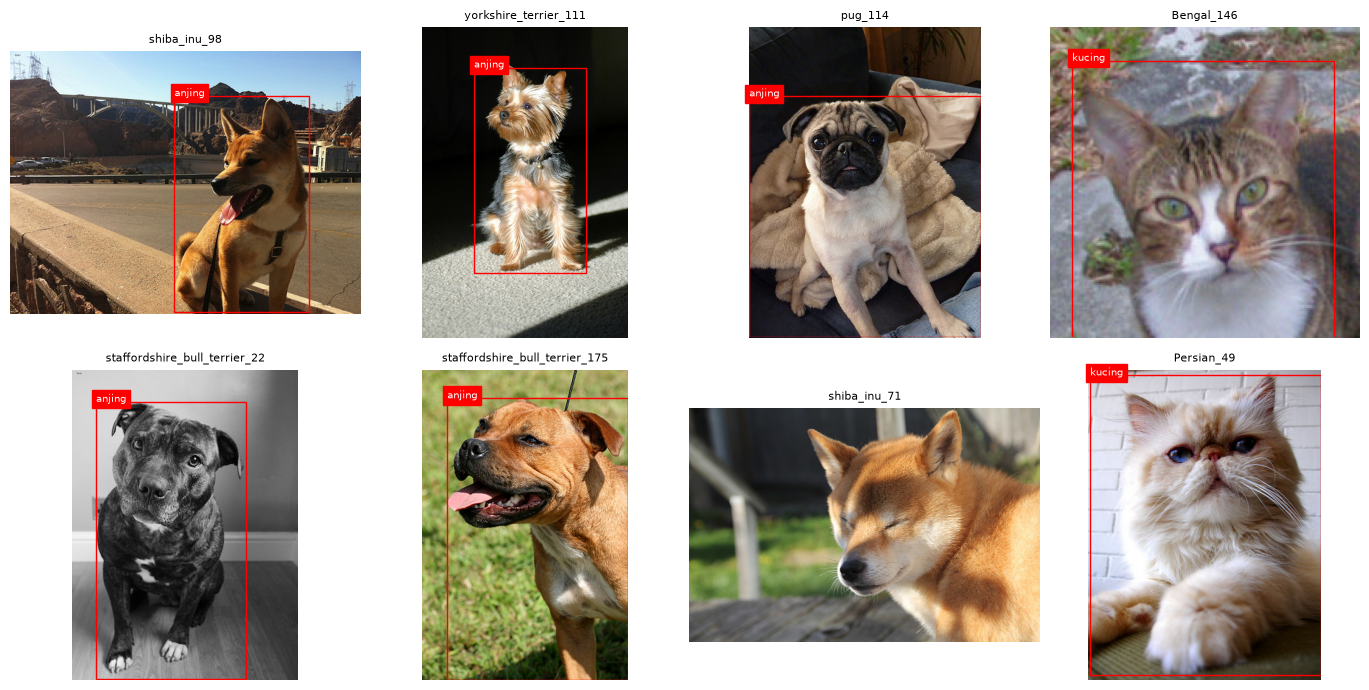

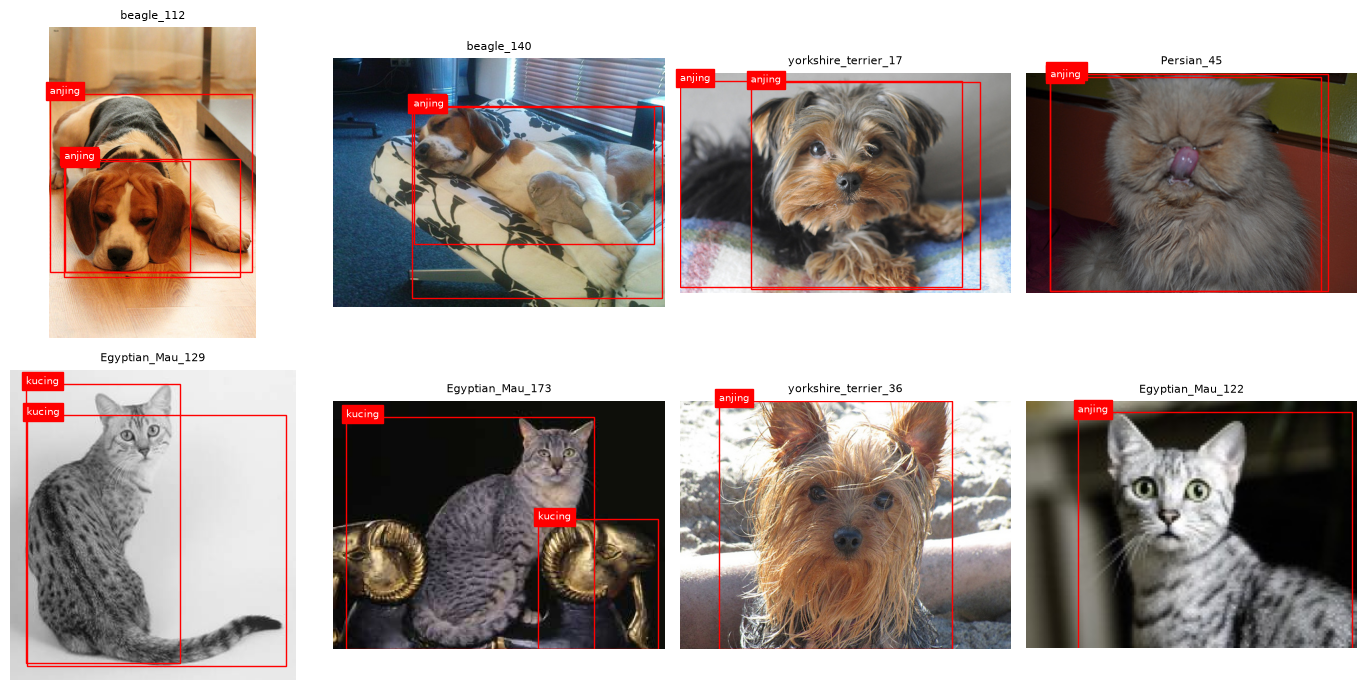

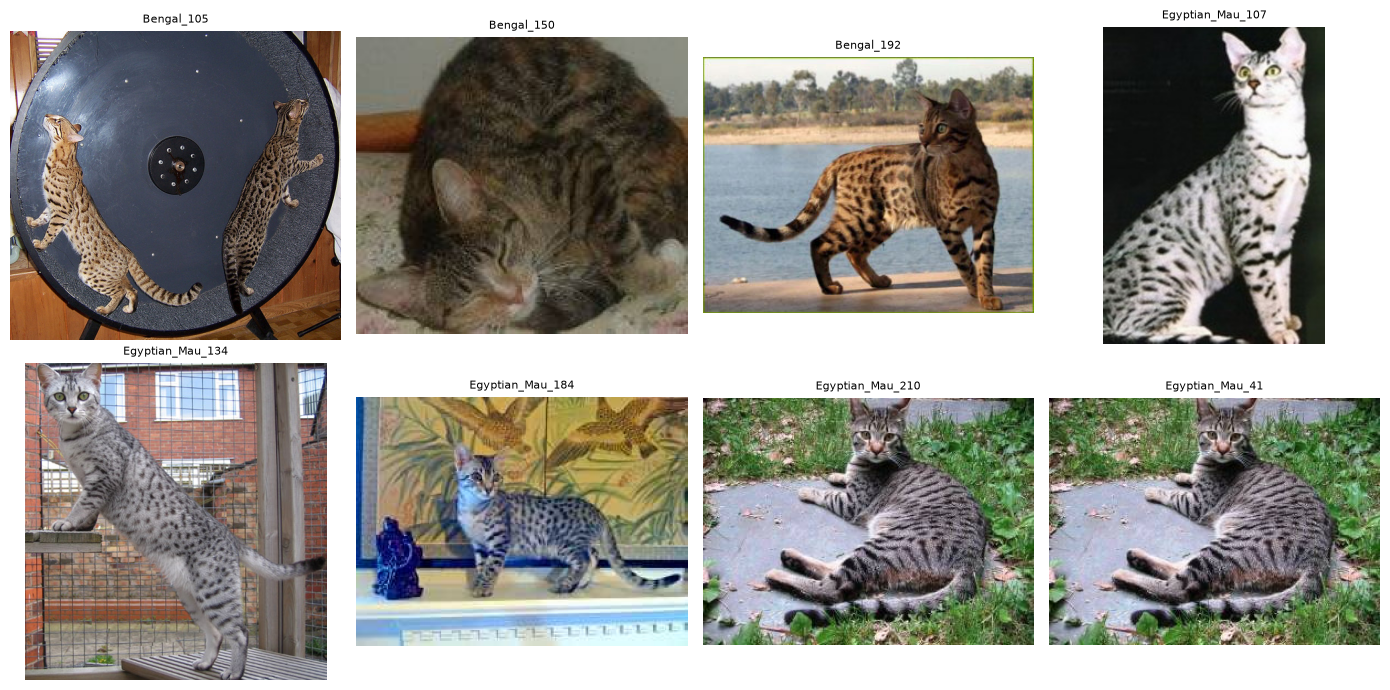

In [5]:
def show_boxes(names, file_name):
    fig, axes = plt.subplots(2, N_GRID // 2, figsize=(14, 7))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, name in zip(axes.ravel(), names):
        image = Image.open(f"{IMAGE_FOLDER}/{name}{IMAGE_EXTENSION}").convert("RGB")
        ax.imshow(image)
        for line in open(f"{LABEL_FOLDER}/{name}.txt").read().splitlines():
            class_id, cx, cy, width, height = line.split()
            box_width = float(width) * image.width
            box_height = float(height) * image.height
            left = float(cx) * image.width - box_width / 2
            top = float(cy) * image.height - box_height / 2
            ax.add_patch(Rectangle((left, top), box_width, box_height, fill=False, color="red"))
            ax.text(left, top, CLASS_NAMES[int(class_id)], color="white", backgroundcolor="red",
                    fontsize=7)
        ax.set_title(name, fontsize=8)
    plt.tight_layout()
    fig.savefig(file_name, dpi=80)
    plt.show()


detected = summary[summary["n_boxes"] > 0]
show_boxes(summary.sample(N_GRID, random_state=SEED)["image"], f"{OUTPUT_FOLDER}/grid_acak.png")
show_boxes(detected.sort_values("min_conf")["image"].head(N_GRID), f"{OUTPUT_FOLDER}/grid_ragu.png")
undetected = summary[summary["n_boxes"] == 0]
show_boxes(undetected["image"].head(N_GRID), f"{OUTPUT_FOLDER}/grid_tanpa_deteksi.png")

## Koreksi: hapus baris, ubah kelas
Cara tercepat tetap membuka file `<OUTPUT_FOLDER>/labels_auto/<nama>.txt` lalu mengedit
barisnya langsung.

In [6]:
for name in DELETE_ROWS:
    label_file = f"{LABEL_FOLDER}/{name}.txt"
    lines = open(label_file).read().splitlines()
    kept = []
    for line_number in range(len(lines)):
        if line_number not in DELETE_ROWS[name]:
            kept.append(lines[line_number])
    with open(label_file, "w") as file:
        file.write("\n".join(kept))

for name in CHANGE_CLASS:
    label_file = f"{LABEL_FOLDER}/{name}.txt"
    lines = open(label_file).read().splitlines()
    for line_number in CHANGE_CLASS[name]:
        box_numbers = lines[line_number].split(" ", 1)[1]     # "cx cy w h" tanpa kelas
        lines[line_number] = f"{CHANGE_CLASS[name][line_number]} {box_numbers}"
    with open(label_file, "w") as file:
        file.write("\n".join(lines))

## Koreksi: tambah kotak manual (koordinat piksel → format YOLO)

In [7]:
for name in ADD_BOXES:
    image = Image.open(f"{IMAGE_FOLDER}/{name}{IMAGE_EXTENSION}")
    new_lines = ""
    for class_id, left, top, right, bottom in ADD_BOXES[name]:
        cx = (left + right) / 2 / image.width
        cy = (top + bottom) / 2 / image.height
        width = (right - left) / image.width
        height = (bottom - top) / image.height
        new_lines = new_lines + f"\n{class_id} {cx:.6f} {cy:.6f} {width:.6f} {height:.6f}"
    with open(f"{LABEL_FOLDER}/{name}.txt", "a") as file:
        file.write(new_lines)

## Susun folder YOLO: `images/train`, `images/val`, `labels/train`, `labels/val`, `data.yaml`
Gambar **disimpan ulang** sebagai JPEG RGB asli (bukan sekadar disalin), karena YOLO membaca
gambar latih dengan OpenCV yang gagal pada GIF berekstensi `.jpg`.
`DATASET_FOLDER` dihapus lalu dibuat ulang setiap kali sel ini jalan.

In [8]:
shutil.rmtree(DATASET_FOLDER, ignore_errors=True)     # mulai dari folder kosong
train_names, val_names = train_test_split(image_names, test_size=VAL_FRACTION,
                                          random_state=SEED)
for part, names in [("train", train_names), ("val", val_names)]:
    os.makedirs(f"{DATASET_FOLDER}/images/{part}")
    os.makedirs(f"{DATASET_FOLDER}/labels/{part}")
    for name in names:
        image = Image.open(f"{IMAGE_FOLDER}/{name}{IMAGE_EXTENSION}").convert("RGB")
        image.save(f"{DATASET_FOLDER}/images/{part}/{name}.jpg", "JPEG")
        shutil.copy(f"{LABEL_FOLDER}/{name}.txt", f"{DATASET_FOLDER}/labels/{part}")

dataset_path = os.path.abspath(DATASET_FOLDER).replace("\\", "/")   # YOLO butuh path lengkap
yaml_text = f"path: {dataset_path}\ntrain: images/train\nval: images/val\nnames:\n"
for class_id in CLASS_NAMES:
    yaml_text = yaml_text + f"  {class_id}: {CLASS_NAMES[class_id]}\n"
with open(f"{DATASET_FOLDER}/data.yaml", "w") as file:
    file.write(yaml_text)
print(yaml_text)
print("train:", len(train_names), "| val:", len(val_names))

path: Z:/GEMASTIK/Vignate-GEMASTIK/outputs/vision/anotasi_deteksi/dataset_auto
train: images/train
val: images/val
names:
  0: kucing
  1: anjing

train: 240 | val: 60


## Fine-tune singkat dari bobot pretrained, lalu mAP di data val
mAP di sini diukur terhadap label hasil anotasi kita sendiri, jadi tinggi belum tentu benar.

In [9]:
model = YOLO(WEIGHTS)
model.train(data=f"{DATASET_FOLDER}/data.yaml", epochs=EPOCHS, imgsz=IMAGE_SIZE,
            batch=BATCH_SIZE, workers=0, device=DEVICE, project=RUNS_FOLDER, name="train",
            exist_ok=True, plots=False, seed=SEED)

model = YOLO(model.trainer.best)        # file bobot terbaik hasil latih
metrics = model.val(data=f"{DATASET_FOLDER}/data.yaml", imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
                    workers=0, device=DEVICE, project=RUNS_FOLDER, name="val", exist_ok=True,
                    plots=False, verbose=False)
print("mAP50:", round(metrics.box.map50, 4), "| mAP50-95:", round(metrics.box.map, 4))

New https://pypi.org/project/ultralytics/8.4.184 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.172  Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../../../outputs/vision/anotasi_deteksi/dataset_auto/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=../../../pretrained/yolov8n/yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=Tr

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 87% ━━━━━━━━━━── 7/8 7.3it/s 0.9s<0.1s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 8.2it/s 1.0s

                   all         60         63      0.785      0.792      0.788      0.562


Speed: 0.2ms preprocess, 7.5ms inference, 0.0ms loss, 1.6ms postprocess per image


mAP50: 0.7881 | mAP50-95: 0.5622


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)
Di Oxford-IIIT Pet, nama file berhuruf depan kapital = kucing, huruf kecil = anjing. Label
otomatis dianggap benar bila kelas kotak pertamanya sama dengan spesies dari nama file.

In [10]:
correct = 0
wrong = 0
for name in image_names:
    lines = open(f"{LABEL_FOLDER}/{name}.txt").read().splitlines()
    if len(lines) == 0:
        continue
    true_class = 1
    if name[0].isupper():
        true_class = 0
    if int(lines[0].split()[0]) == true_class:
        correct = correct + 1
    else:
        wrong = wrong + 1
missing = len(image_names) - correct - wrong
print("spesies benar:", correct, "| salah:", wrong, "| tanpa kotak:", missing)

spesies benar: 278 | salah: 9 | tanpa kotak: 13


## Masalah umum
- **`CUDA out of memory` di sel Auto-label:** jangan kirim semua gambar sekaligus ke
  `model.predict`; proses satu per satu seperti di sel ini.
- **`Image Not Found` / gagal baca saat training:** file bukan JPEG asli (GIF/PNG). Simpan ulang
  dengan PIL `convert("RGB")` seperti di sel Susun folder.
- **Hampir semua gambar tanpa deteksi:** objek soal bukan salah satu dari 80 kelas COCO.
  Auto-label tidak membantu; labeli manual (CVAT/Label Studio).
- **Kelas tertukar:** cek `CLASS_MAP` (nomor dataset COCO) dan urutan `CLASS_NAMES`.